# PID Control of a First Order System

## Preparations

Here we import all necessary libraries.

In [206]:
from IPython.core.display import HTML
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans",
    "font.size": 10,
})

from sympy import *
from sympy.plotting import plot

from mathprint import *

These are some variables that we are going to use: 

$t, s, \tau, \omega, \omega_n, \zeta$

In [207]:
from sympy.physics.control.lti import TransferFunction
Kp, Ki, Kd = symbols('K_p K_i K_d', positive=True)

t       = symbols('t', positive=True)
s       = symbols('s', complex=True)
tau     = symbols('tau', positive=True)

omega   = symbols("omega", positive=True)
omega_n = symbols('omega_n', positive=True)
zeta    = symbols('zeta', positive=True)

Let us define some helper functions.

In [208]:
def laplace(f):
    F = laplace_transform(f, t, s, noconds=True)
    return F

def ilaplace(F):
    f = inverse_laplace_transform(F, s, t)
    return f

def frac_to_tf(frac):
    return TransferFunction(fraction(frac)[0], fraction(frac)[1], s)

## System and the control equations

![](./images/p13.png)

The diagram above corresponds to a unity-feedback loop with

$$
G(s)=K_p+\frac{K_i}{s}+K_ds
$$

and plant

$$
H(s)=\frac{1}{\tau s+1}.
$$

Thus, the closed-loop transfer function is

$$
\frac{C(s)}{R(s)}
=
\frac{\left(K_p+\frac{K_i}{s}+K_ds\right)\frac{1}{\tau s+1}}
{1+\left(K_p+\frac{K_i}{s}+K_ds\right)\frac{1}{\tau s+1}}
=
\frac{K_d s^2+K_p s+K_i}
{(\tau+K_d)s^2+(1+K_p)s+K_i}
$$



In [209]:
H = 1 / (tau*s+1)
G = Kp + Ki/s + Kd*s   # PID-control
Q = factor(((G*H / (1 + G*H))))

print("first-order system:")
mprint("H(s)=", latex(H))

print("PID-control:")
mprint("G(s)= ", latex(G))

print("the resulting closed-loop system:")
mprint("Q(s)=", latex(Q))

first-order system:


<IPython.core.display.Math object>

PID-control:


<IPython.core.display.Math object>

the resulting closed-loop system:


<IPython.core.display.Math object>

## First order system with P-control 

Closed-loop transfer function:

In [210]:
Qp = simplify(Q.subs(([Kd, 0],
                      [Ki, 0])))

mprint(latex(Qp))

<IPython.core.display.Math object>

The controlled system remains a first order system. $K_p$ changes the pole location.
New pole location:

### Closed-loop poles and zeros

In [211]:
f = frac_to_tf(Qp)
zerosp = f.zeros()
polesp = f.poles()

print("closed-loop zeros:")
mprint(latex(zerosp))
       
print("closed-loop poles:")
mprint(latex(polesp))

closed-loop zeros:


<IPython.core.display.Math object>

closed-loop poles:


<IPython.core.display.Math object>

### Step response

Let us define some numerical values for our simulations.

In [212]:
tau_ = 1
Kp_  = [1, 5, 10, 20]

We simply perform an inverse Laplace operation to $C(s)$ and obtain $c(t)$ as the result. Additionally, we will also compute the steady state-value for the output ($c_{ss}$).

In [213]:
cp = ilaplace(Qp * 1/s)

cssp = simplify(limit(cp, t, 'oo'))
c0p  = limit(cp, t, 0)

mprintb("c(t) = ", latex(cp))
mprintb("c_{ss} = ", latex(cssp))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

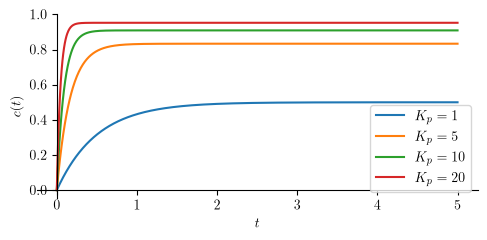

In [214]:
p = [plot(cp.subs(([tau, tau_], [Kp, Kp_[j]])), (t, 0, 5), size=(5, 2.5), ylabel='$c(t)$', show=False, legend=True) for j in range(len(Kp_))]

for j in range(len(p)):
    p[j][0].label = "$K_p=" + str(Kp_[j]) + "$"
    if j > 0:
        p[0].append(p[j][0])

p[0].show()

## First-order system with PD-control 

Closed-loop transfer function:

In [215]:
Qpd = simplify(Q.subs(Ki, 0))

mprint(latex(Qpd))

<IPython.core.display.Math object>

### Closed-loop poles and zeros

In [216]:
f = frac_to_tf(Qpd)
zerospd = f.zeros()
polespd = f.poles()

print("closed-loop zeros:")
mprint(latex(zerospd))

print("closed-loop zeros:")
mprint(latex(polespd))

closed-loop zeros:


<IPython.core.display.Math object>

closed-loop zeros:


<IPython.core.display.Math object>

### Step response

We simply perform an inverse Laplace operation to $C(s)$ and obtain $c(t)$ as the result. Additionally, we will also compute the steady state-value for the output ($c_{ss}$).

A phenomenon that can be observed in a derivative control is the __"kick"__ that happens when a step input is applied to the controlled system. Because of the kick, system output does not start from zero. 

In [217]:
cpd   = logcombine(ilaplace(Qpd * 1/s))
csspd = limit(cpd, t, 'oo')
c0pd  = limit(cpd, t, 0)

mprintb("c(t) = ", latex(cpd))
mprintb("c_{ss} = ", latex(csspd))
mprintb("c(0) = ", latex(c0pd))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Next, we set up arbitrary numerical values to some parameters and run sumulate the controlled system.

In [218]:
tau_ = 1
Kp_  = 20
Kd_  = [0.1, 0.5, 1]

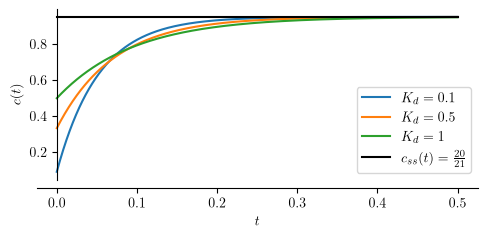

In [219]:
p = [plot(cpd.subs(([tau, tau_], [Kp, Kp_],[Kd, Kd_[j]])), (t, 0, .5), size=(5, 2.5), ylabel='$c(t)$', show=False, legend=True, axis_center=[0,0]) for j in range(len(Kd_))]

for j in range(len(p)):
    p[j][0].label = "$K_d=" + str(Kd_[j]) + "$"
    if j > 0:
        p[0].append(p[j][0])

q = plot(csspd.subs(Kp, Kp_), (t, 0, .5), line_color='k', show=False)

q[0].label = "$ c_{ss} (t) = " + latex(csspd.subs(Kp, Kp_)) + " $"
p[0].append(q[0])
p[0].show()


## First-order system with PI-control 

Closed-loop transfer function:

In [220]:
Qpi = simplify(Q.subs(Kd, 0))

mprintb(latex(Qpi))

<IPython.core.display.Math object>

### Closed-loop poles and zeros

In [221]:
f = frac_to_tf(Qpi)
zerospi = f.zeros()
polespi = f.poles()

print("closed-loop zeros:")
mprint(latex(zerospi))

print("closed-loop zeros:")
mprint(latex(polespi))

closed-loop zeros:


<IPython.core.display.Math object>

closed-loop zeros:


<IPython.core.display.Math object>

### Step response

We simply perform an inverse Laplace operation to $C(s)$ and obtain $c(t)$ as the result. Additionally, we will also compute the steady state-value for the output ($c_{ss}$).

In [222]:
cpi = ilaplace(Qpi * 1/s)
cpi = sum([simplify(cpi.args[j]) for j in range(len(cpi.args))])

csspi = limit(cpi, t, 'oo')

mprintb("c(t) = ", latex(cpi))
mprintb("c_{ss} = ", latex(csspi))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Next, we set up arbitrary numerical values to some parameters and run sumulate the controlled system.

In [223]:
tau_ = 1
Kp_ = 20
Ki_ = [1, 10, 100, 1000]
Kd_ = 0

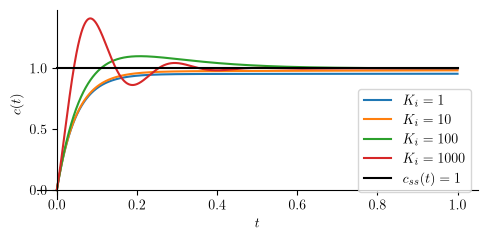

In [224]:
p = [plot(cpi.subs(([tau, tau_], [Kp, Kp_],[Ki, Ki_[j]])), (t, 0, 1), size=(5, 2.5), ylabel='$c(t)$', show=False, legend=True) for j in range(len(Ki_))]

for j in range(len(p)):
    p[j][0].label = "$K_i=" + str(Ki_[j]) + "$"
    if j > 0:
        p[0].append(p[j][0])

q = plot(csspi.subs(Kp, Kp_), (t, 0, 1), line_color='k', show=False)
q[0].label = "$ c_{ss} (t) = " + latex(csspi.subs(Kp, Kp_)) + " $"
p[0].append(q[0])
p[0].show()


## First-order system with PID-control 

### Closed-loop poles and zeros

In [225]:
f = frac_to_tf(Q)
zerospid = f.zeros()
polespid = f.poles()

print("Closed-loop zeros:")
mprint(latex(zerospid))
       
print("Closed-loop poles:")
mprint(latex(polespid))

Closed-loop zeros:


<IPython.core.display.Math object>

Closed-loop poles:


<IPython.core.display.Math object>

### Step response

In [226]:
cpid   = logcombine(ilaplace(Q * 1/s))
csspid = limit(cpid, t, 'oo')
c0pid  = limit(cpid, t, 0)

mprintb("c(t) = ", latex(cpid))
mprintb("c_{ss} = ", latex(csspid))
mprintb("c(0) = ", latex(c0pid))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Compact Engineering Form

Unfortunately, there is no consistently clean automatic SymPy path from a messy `ilaplace()` result to the compact engineering form

$$
c(t)=c_{DC}+e^{-\sigma t}
\left(
A\cos(\omega_d t)+B\sin(\omega_d t)
\right).
$$

Therefore, instead of forcing SymPy to rearrange the expression automatically, we will start from the complete solution for PID control of a first-order system and decompose it manually into three parts:

$$
c(t)=c_1(t)+c_2(t)c_3(t),
$$

where $c_1(t)$ is the DC component, $c_2(t)$ is the sinusoidal component, and $c_3(t)$ is the exponential decay envelope.

In [227]:
A0 = Kd + tau
B0 = Kp + 1
C0 = Ki

D = 4*A0*C0 - B0**2

sigma = B0/(2*A0)
omega_d = sqrt(D)/(2*A0)

A = -tau/A0
B = (tau*B0 - 2*A0)/(A0*sqrt(D))

cpid_compact = 1 + exp(-sigma*t)*(A*cos(omega_d*t) + B*sin(omega_d*t))

mprint(r"\sigma = ", latex(sigma))
mprint(r"\omega_d = ", latex(omega_d))
mprint(r"A = ", latex(A))
mprint(r"B = ", latex(B))
mprintb("c(t) = ", latex(cpid_compact))

check = simplify(cpid - cpid_compact)
print("check = ", check)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

check =  0


In [228]:
c_lst = Add.make_args(cpid_compact) # separate cn
c1 = c_lst[0]
c2 = numer(c_lst[1])
c3 = 1 / denom(c_lst[1])

mprintb('c_{1}(t)=', latex(c1))
mprintb('c_{2}(t)=', latex(c2))
mprintb('c_{3}(t)=', latex(c3))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Deriving a tuning formula

Previously, we found that PID control of a first-order system results in the closed-loop transfer function

$$
Q(s)=\frac{K_d s^2+K_p s+K_i}
{(\tau+K_d)s^2+(1+K_p)s+K_i}.
$$

We will now derive a simple tuning formula by choosing the desired closed-loop poles. For a second-order system, these poles can be specified using the damping ratio $\zeta$ and the natural frequency $\omega_n$.


In [229]:
mprint("Q(s)=",latex(Q))

num, denom = Q.as_numer_denom()
print("--- characteristic equation ---")
mprint(latex(Eq(denom, 0)))

char_pid = collect(denom, [s, s**2])
char_pid = char_pid / char_pid.coeff(s,2)
char_pid = collect(expand(char_pid), s, together)
mprintb(latex(Eq(char_pid, 0)))


<IPython.core.display.Math object>

--- characteristic equation ---


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [230]:
# Characteristic equation of the closed-loop system
char_desired = s**2 + 2*zeta*omega_n*s + omega_n**2

mprint("PID: ", latex(char_pid))
mprint("Desired: ", latex(char_desired))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

By comparing the coefficients, we find:

In [248]:
eq1 = Eq(char_pid.coeff(s, 0), char_desired.coeff(s, 0))
mprint(latex(eq1))

<IPython.core.display.Math object>

In [245]:
eq2 = Eq(char_pid.coeff(s, 1), char_desired.coeff(s, 1))
mprint(latex(eq2))

<IPython.core.display.Math object>

We can now solve these equations for $K_p$ and $K_i$. Note that we have two equations but three controller gains. Therefore, $K_d$ must still be selected separately.

In [247]:
sol_pid = solve([eq1, eq2], (Kp, Ki))

mprintb("K_p = ", latex(factor(sol_pid[Kp])))
mprintb("K_i = ", latex(factor(sol_pid[Ki])))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The tuning formula for PID control is thus

$$
\boxed{K_p=2\zeta\omega_n(\tau+K_d)-1}
$$

$$
\boxed{K_i=\omega_n^2(\tau+K_d).}
$$

These formulas place the closed-loop poles at the desired locations. We should also check that the resulting controller gains are appropriate for our system.

### Tuning a PI controller

If we do not need the derivative action, simply let $K_d=0$. We then obtain a PI controller with only two gains to determine.

In [234]:
sol_pi = {key: simplify(value.subs(Kd, 0)) for key, value in sol_pid.items()}

mprintb("K_p = ", latex(sol_pi[Kp]))
mprintb("K_i = ", latex(sol_pi[Ki]))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Numerical example

Let us assume that $\tau=1$. We would like to have a damping ratio $\zeta=0.7$ and a natural frequency $\omega_n=4$ rad/s.

First, we calculate the gains for PI control ($K_d=0$). Then, for comparison, we choose $K_d=0.2$ and calculate the remaining gains for PID control.

In [235]:
tau_design = 1
zeta_design = Rational(7, 10)
omega_n_design = 4
Kd_design = Rational(1, 5)

settings = {tau: tau_design, zeta: zeta_design, omega_n: omega_n_design}

Kp_pi = sol_pi[Kp].subs(settings)
Ki_pi = sol_pi[Ki].subs(settings)

Kp_pid = sol_pid[Kp].subs(settings).subs(Kd, Kd_design)
Ki_pid = sol_pid[Ki].subs(settings).subs(Kd, Kd_design)

print("PI controller:")
mprintb("K_p = ", latex(Kp_pi))
mprintb("K_i = ", latex(Ki_pi))

print("PID controller:")
mprintb("K_p = ", latex(Kp_pid))
mprintb("K_i = ", latex(Ki_pid))
mprintb("K_d = ", latex(Kd_design))

PI controller:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

PID controller:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Closed-loop poles and step response

Let us verify the closed-loop poles, and then compare the step responses of the two controllers. Both controllers are designed for the same $\zeta$ and $\omega_n$.

In [236]:
Q_pi_tuned = factor(Q.subs({tau: tau_design, Kp: Kp_pi, Ki: Ki_pi, Kd: 0}))
Q_pid_tuned = factor(Q.subs({tau: tau_design, Kp: Kp_pid, Ki: Ki_pid, Kd: Kd_design}))

print("PI closed-loop poles:")
mprint(latex(frac_to_tf(Q_pi_tuned).poles()))

print("PID closed-loop poles:")
mprint(latex(frac_to_tf(Q_pid_tuned).poles()))

PI closed-loop poles:


<IPython.core.display.Math object>

PID closed-loop poles:


<IPython.core.display.Math object>

We will also plot the step response of the standard second-order system with the same characteristic equation. This provides a useful reference for comparison.

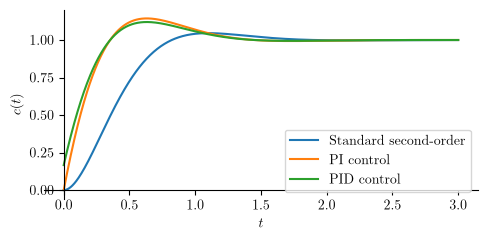

In [237]:
c_pi_tuned = simplify(cpid_compact.subs({tau: tau_design, Kp: Kp_pi,
                                               Ki: Ki_pi, Kd: 0}))
c_pid_tuned = simplify(cpid_compact.subs({tau: tau_design, Kp: Kp_pid,
                                                Ki: Ki_pid, Kd: Kd_design}))

Q_desired = omega_n**2 / char_desired
c_desired = simplify(ilaplace((Q_desired/s).subs({zeta: zeta_design,
                                                omega_n: omega_n_design})))

p = plot(c_desired, (t, 0, 3), size=(5, 2.5), ylabel='$c(t)$',
         show=False, legend=True)
p[0].label = 'Standard second-order'

q = plot(c_pi_tuned, (t, 0, 3), show=False)
q[0].label = 'PI control'
p.append(q[0])

q = plot(c_pid_tuned, (t, 0, 3), show=False)
q[0].label = 'PID control'
p.append(q[0])

p.show()

We can see that matching the poles does **not** necessarily give the same step response. Although the characteristic equations are identical, the closed-loop transfer functions have different zeros.

In particular, the ideal PID controller also produces an initial jump in the output when the reference is a step. Let us check the initial values.

In [238]:
mprintb("c_{PI}(0) = ", latex(limit(c_pi_tuned, t, 0, dir='+')))
mprintb("c_{PID}(0) = ", latex(limit(c_pid_tuned, t, 0, dir='+')))

mprintb(r"c_{PI}(\infty) = ", latex(limit(c_pi_tuned, t, oo)))
mprintb(r"c_{PID}(\infty) = ", latex(limit(c_pid_tuned, t, oo)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Thus, pole placement is a convenient way to calculate the controller gains, but we must still check the actual closed-loop response. In practice, derivative action is usually filtered, or applied to the measured output rather than directly to a step in the reference.

## Summary

In [239]:
from pandas import DataFrame, set_option
from IPython.display import Markdown, display

def makelatex(args):
    return ["${}$".format(latex(a)) for a in args]

descs = ["P", 
         "PD",
         "PI",
         "PID"]

css_label = [cssp, csspd, csspi, csspid]
c_label   = [cp, cpd, cpi, cpid]
cl_zeros  = [zerosp, zerospd, zerospi, zerospid]
cl_poles  = [polesp, polespd, polespi, polespid]
kicks     = [0, c0pd, 0, c0pid]


dic1 = {''         : makelatex(descs), 
        '$c_{ss}$' : makelatex(css_label),
        '$c(0)$'   : makelatex(kicks)}

dic2 = {''         : makelatex(descs), 
        'Zeros'    : makelatex(cl_zeros),
        'Poles'    : makelatex(cl_poles)}

df1 = DataFrame(dic1)
df2 = DataFrame(dic2)

### Initial and steady-state output for unit-step input

In [240]:
Markdown(df1.to_markdown(index=False))

|                       | $c_{ss}$                                                                                                                                                                                                                                                                                                                                                                                                                 | $c(0)$                       |
|:----------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:-----------------------------|
| $\mathtt{\text{P}}$   | $\frac{K_{p}}{K_{p} + 1}$                                                                                                                                                                                                                                                                                                                                                                                                | $0$                          |
| $\mathtt{\text{PD}}$  | $\frac{K_{p}}{K_{p} + 1}$                                                                                                                                                                                                                                                                                                                                                                                                | $\frac{K_{d}}{K_{d} + \tau}$ |
| $\mathtt{\text{PI}}$  | $1$                                                                                                                                                                                                                                                                                                                                                                                                                      | $0$                          |
| $\mathtt{\text{PID}}$ | $\frac{K_{d}^{3} \sqrt{4 K_{d} K_{i} + 4 K_{i} \tau - K_{p}^{2} - 2 K_{p} - 1} + 3 K_{d}^{2} \tau \sqrt{4 K_{d} K_{i} + 4 K_{i} \tau - K_{p}^{2} - 2 K_{p} - 1} + 3 K_{d} \tau^{2} \sqrt{4 K_{d} K_{i} + 4 K_{i} \tau - K_{p}^{2} - 2 K_{p} - 1} + \tau^{3} \sqrt{4 K_{d} K_{i} + 4 K_{i} \tau - K_{p}^{2} - 2 K_{p} - 1}}{\left(K_{d} + \tau\right)^{3} \sqrt{4 K_{d} K_{i} + 4 K_{i} \tau - K_{p}^{2} - 2 K_{p} - 1}}$ | $\frac{K_{d}}{K_{d} + \tau}$ |

### Zeros and poles

In [241]:
Markdown(df2.to_markdown(index=False))

|                       | Zeros                                                                                                                                                                         | Poles                                                                                                                                                                                                                                                                                                                           |
|:----------------------|:------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| $\mathtt{\text{P}}$   | $\left[ \right]$                                                                                                                                                              | $\left[ - \frac{K_{p} + 1}{\tau}\right]$                                                                                                                                                                                                                                                                                        |
| $\mathtt{\text{PD}}$  | $\left[ - \frac{K_{p}}{K_{d}}\right]$                                                                                                                                         | $\left[ - \frac{K_{p} + 1}{K_{d} + \tau}\right]$                                                                                                                                                                                                                                                                                |
| $\mathtt{\text{PI}}$  | $\left[ - \frac{K_{i}}{K_{p}}\right]$                                                                                                                                         | $\left[ - \frac{K_{p} + 1}{2 \tau} - \frac{\sqrt{- 4 K_{i} \tau + K_{p}^{2} + 2 K_{p} + 1}}{2 \tau}, \  - \frac{K_{p} + 1}{2 \tau} + \frac{\sqrt{- 4 K_{i} \tau + K_{p}^{2} + 2 K_{p} + 1}}{2 \tau}\right]$                                                                                                                     |
| $\mathtt{\text{PID}}$ | $\left[ - \frac{K_{p}}{2 K_{d}} - \frac{\sqrt{- 4 K_{d} K_{i} + K_{p}^{2}}}{2 K_{d}}, \  - \frac{K_{p}}{2 K_{d}} + \frac{\sqrt{- 4 K_{d} K_{i} + K_{p}^{2}}}{2 K_{d}}\right]$ | $\left[ - \frac{K_{p} + 1}{2 \left(K_{d} + \tau\right)} - \frac{\sqrt{- 4 K_{d} K_{i} - 4 K_{i} \tau + K_{p}^{2} + 2 K_{p} + 1}}{2 \left(K_{d} + \tau\right)}, \  - \frac{K_{p} + 1}{2 \left(K_{d} + \tau\right)} + \frac{\sqrt{- 4 K_{d} K_{i} - 4 K_{i} \tau + K_{p}^{2} + 2 K_{p} + 1}}{2 \left(K_{d} + \tau\right)}\right]$ |

### Resulting second order system

In [242]:
mprintb("c(t) = ", latex(cpid_compact))

print("--- or ---")

mprint('c(t)=c_1(t)+c_2(t)c_3(t)')

mprintb('c_{1}(t)=', latex(c1))
mprintb('c_{2}(t)=', latex(c2))
mprintb('c_{3}(t)=', latex(c3))

<IPython.core.display.Math object>

--- or ---


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>